In [1]:
import pandas as pd
import numpy as np

df = pd.DataFrame({"packets": [10, 500, 12], "label": ["normal", "attack", "normal"]})
print(df)
print("Mean packets:", np.mean(df["packets"]))

   packets   label
0       10  normal
1      500  attack
2       12  normal
Mean packets: 174.0


In [1]:
import tracemalloc

# --- Test 1: Normal Class ---
class Normal:
    def __init__(self, a, b, c):
        self.a = a
        self.b = b
        self.c = c

tracemalloc.start()
list1 = [Normal(i, i, i) for i in range(10000)]
_, peak1 = tracemalloc.get_traced_memory()
tracemalloc.stop()

# --- Test 2: Slots Class ---
class Fast:
    __slots__ = ['a', 'b', 'c']
    def __init__(self, a, b, c):
        self.a = a
        self.b = b
        self.c = c

tracemalloc.start()
list2 = [Fast(i, i, i) for i in range(10000)]
_, peak2 = tracemalloc.get_traced_memory()
tracemalloc.stop()

print(f"Normal: {peak1/1024:.1f} KB")
print(f"Slots:  {peak2/1024:.1f} KB")
print(f"Bachat: {(peak1-peak2)/1024:.1f} KB ({(1-peak2/peak1)*100:.0f}%)")

Normal: 1844.8 KB
Slots:  910.8 KB
Bachat: 934.0 KB (51%)


In [2]:
from sklearn.linear_model import LogisticRegression

X = [[10], [12], [15], [480], [500], [520]]   # packets per second
y = [0, 0, 0, 1, 1, 1]                        # 0 = normal, 1 = attack

model = LogisticRegression()
model.fit(X, y)
print("Prediction for 20 packets:", model.predict([[20]]))
print("Prediction for 490 packets:", model.predict([[490]]))

Prediction for 20 packets: [0]
Prediction for 490 packets: [1]


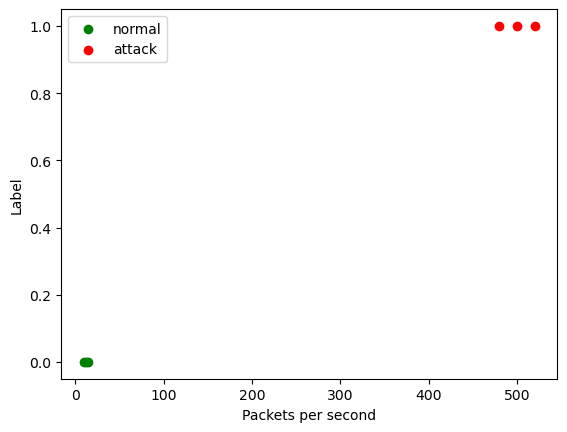

In [3]:
import matplotlib.pyplot as plt

plt.scatter([10, 12, 15], [0, 0, 0], color="green", label="normal")
plt.scatter([480, 500, 520], [1, 1, 1], color="red", label="attack")
plt.xlabel("Packets per second")
plt.ylabel("Label")
plt.legend()
plt.show()

In [4]:
import tensorflow as tf
print("TensorFlow OK:", tf.__version__)

TensorFlow OK: 2.21.0
